# Advanced Feature Engineering & Dimensionality Reduction
### SGRH Lung Cancer Immunotherapy Cohort
**Source Dataset:** `data/processed/ICI_cleaned.xlsx` (Cleaned, Randomized, $N=64$)  
**Engineered Deliverable:** `data/processed/ICI_featured.xlsx` (239 features) & `data/processed/ICI_modeling_ready.xlsx` (122 curated features)  
**Format:** Strictly Excel (`.xlsx`), no CSV output.

---

## 1. Objectives & Methodological Architecture
In a high-dimensional immuno-oncology dataset ($n = 64, p = 180$), raw high-dimensional features suffer from collinearity, uncalibrated scaling, and severe risk of overfitting.
This notebook implements and verifies three pillars of feature engineering:
1. **Proper One-Hot Encoding (OHE):** Explicit categorical dummy matrices for nominal features (Sex, Diet, Histology, Stage, ICI Drug, PD-L1 TPS, MSI status).
2. **Clinical & Inflammatory Kinetic Features:** Body Surface Area (BSA), Ponderal index, Monocyte-to-Lymphocyte Ratio (MLR), Derived NLR (dNLR), Systemic Immune-Inflammation Index proxy, and NLR on-therapy trajectory.
3. **Biomarker Synergy & Cross-Modality Interactions:** Double-positive (TMB-High & PD-L1-High) archetypes, TMB $\times$ PD-L1 product, and TP53 $\times$ TMB interaction.
4. **Biological Pathway Proteomic Signatures (Feature Reduction):** Condensing 92 collinear Olink proteins into 7 biological domain signatures (Cytolytic T-cell activation, Immunosuppression, Pro-inflammatory cytokines, Angiogenesis, Chemokine homing, Myeloid recruitment, and Net Immune Balance).
5. **Data-Driven Dimensionality Reduction via PCA:** Extracting 5 orthogonal principal components capturing **72.3%** of total proteomic variance and 2 components capturing **91.3%** of metabolomic variance.
6. **Feature Pruning & Non-Redundant Curation:** Elimination of collinear reference classes, duplicate indicators, and intermediate audit columns.


In [1]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

featured_path = os.path.join('..', 'data', 'processed', 'ICI_featured.xlsx')
modeling_path = os.path.join('..', 'data', 'processed', 'ICI_modeling_ready.xlsx')

if not os.path.exists(featured_path):
    featured_path = r'c:\Users\SAM\Documents\GitHub\SGRH-Lung Cancer\data\processed\ICI_featured.xlsx'
    modeling_path = r'c:\Users\SAM\Documents\GitHub\SGRH-Lung Cancer\data\processed\ICI_modeling_ready.xlsx'

df_feat = pd.read_excel(featured_path)
df_model = pd.read_excel(modeling_path)

print(f"Complete Featured Dataset: {df_feat.shape[0]} patients x {df_feat.shape[1]} columns")
print(f"Compact Modeling Dataset:  {df_model.shape[0]} patients x {df_model.shape[1]} columns")
print(f"Missing Values across all cells: {df_feat.isna().sum().sum()}")


Complete Featured Dataset: 64 patients x 239 columns
Compact Modeling Dataset:  64 patients x 122 columns
Missing Values across all cells: 0


## 2. Proper One-Hot Encoding Verification
Inspecting the created one-hot dummy columns across demographics, histology, disease stage, drug allocation, and biomarker classes.


In [2]:
ohe_cols = [c for c in df_feat.columns if c.startswith('ohe_')]
print(f"Total One-Hot Encoded Features: {len(ohe_cols)}")

ohe_summary = []
for c in ohe_cols:
    ohe_summary.append({
        'OHE Feature': c,
        'Positive Count (1)': int(df_feat[c].sum()),
        'Percentage (%)': round(df_feat[c].mean() * 100, 1)
    })
df_ohe_summary = pd.DataFrame(ohe_summary)
print(df_ohe_summary.to_string(index=False))

# Verify sum of mutually exclusive groups
print("\nMutual Exclusivity Sanity Checks:")
print(f"  Histology OHE row sums == 1: {((df_feat['ohe_histology_adenocarcinoma'] + df_feat['ohe_histology_squamous'] + df_feat['ohe_histology_large_cell'] + df_feat['ohe_histology_mixed'] + df_feat['ohe_histology_unspecified']) == 1).all()}")
print(f"  Stage OHE row sums == 1:     {((df_feat['ohe_stage_iii'] + df_feat['ohe_stage_iv']) == 1).all()}")
print(f"  Drug OHE row sums == 1:      {((df_feat['ohe_drug_nivolumab'] + df_feat['ohe_drug_pembrolizumab']) == 1).all()}")
print(f"  PD-L1 OHE row sums == 1:     {((df_feat['ohe_pdl1_negative'] + df_feat['ohe_pdl1_intermediate'] + df_feat['ohe_pdl1_high']) == 1).all()}")


Total One-Hot Encoded Features: 21
                 OHE Feature  Positive Count (1)  Percentage (%)
                ohe_sex_male                  42            65.6
              ohe_sex_female                  22            34.4
         ohe_diet_vegetarian                  28            43.8
     ohe_diet_non_vegetarian                  36            56.2
ohe_histology_adenocarcinoma                  22            34.4
      ohe_histology_squamous                  23            35.9
    ohe_histology_large_cell                   4             6.2
         ohe_histology_mixed                   8            12.5
   ohe_histology_unspecified                   7            10.9
               ohe_stage_iii                  39            60.9
                ohe_stage_iv                  25            39.1
          ohe_drug_nivolumab                  38            59.4
      ohe_drug_pembrolizumab                  26            40.6
           ohe_pdl1_negative                  26       

## 3. Clinical & Systemic Inflammatory Kinetic Features
Examining engineered ratios: Body Surface Area (BSA), Derived NLR (dNLR), Monocyte-to-Lymphocyte Ratio (MLR), and dynamic on-treatment inflammatory trajectories.


C:\Users\SAM\AppData\Local\Temp\ipykernel_26116\3974028114.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_feat, x='response_label', y='nlr_delta', palette=['#e74c3c', '#2ecc71'], ax=axes[0])
C:\Users\SAM\AppData\Local\Temp\ipykernel_26116\3974028114.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_feat, x='response_label', y='hem_mlr_delta', palette=['#e74c3c', '#2ecc71'], ax=axes[1])


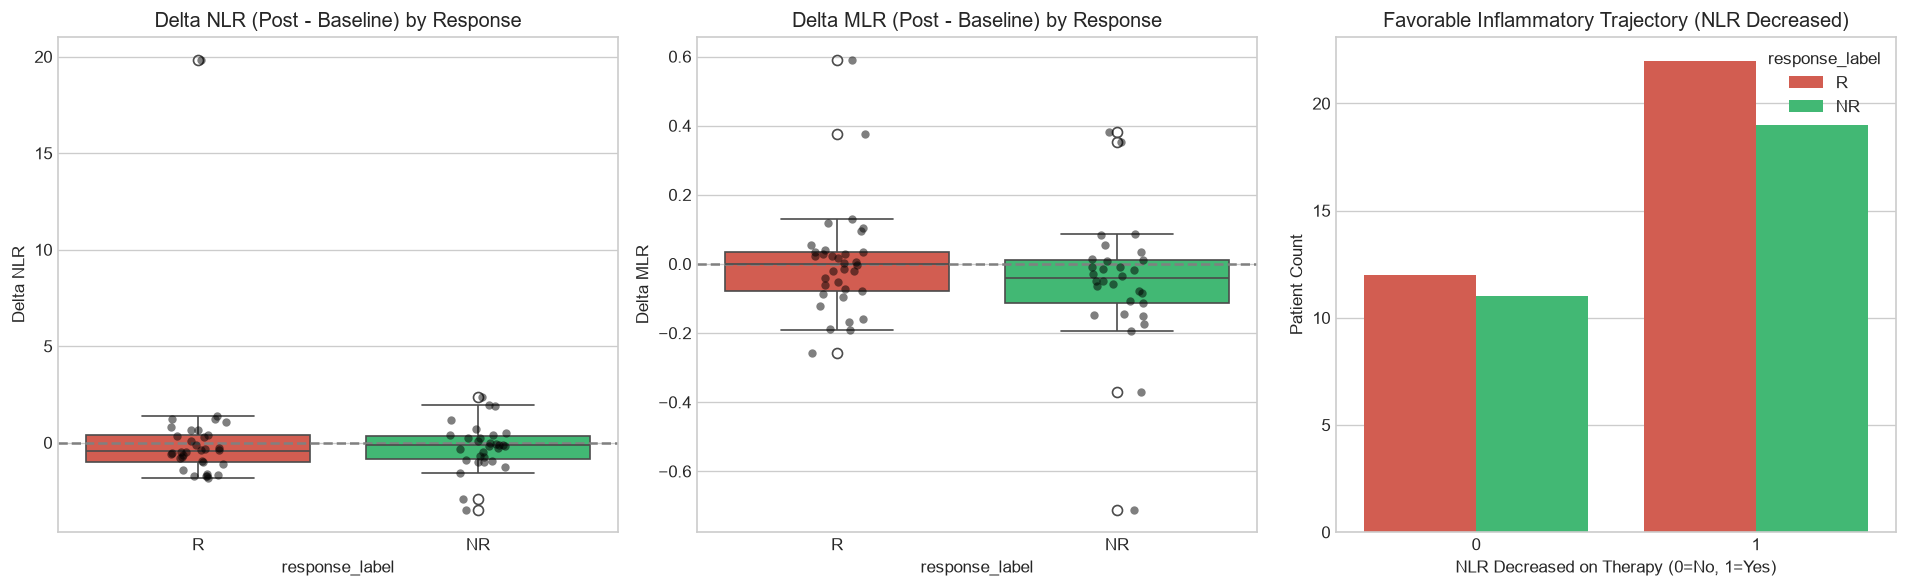

Mann-Whitney U test on Delta NLR (R vs NR): p-value = 5.1408e-01


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Delta NLR by Response
sns.boxplot(data=df_feat, x='response_label', y='nlr_delta', palette=['#e74c3c', '#2ecc71'], ax=axes[0])
sns.stripplot(data=df_feat, x='response_label', y='nlr_delta', color='black', alpha=0.5, ax=axes[0])
axes[0].axhline(0, color='grey', linestyle='--')
axes[0].set_title('Delta NLR (Post - Baseline) by Response')
axes[0].set_ylabel('Delta NLR')

# 2. Delta MLR by Response
sns.boxplot(data=df_feat, x='response_label', y='hem_mlr_delta', palette=['#e74c3c', '#2ecc71'], ax=axes[1])
sns.stripplot(data=df_feat, x='response_label', y='hem_mlr_delta', color='black', alpha=0.5, ax=axes[1])
axes[1].axhline(0, color='grey', linestyle='--')
axes[1].set_title('Delta MLR (Post - Baseline) by Response')
axes[1].set_ylabel('Delta MLR')

# 3. NLR Trajectory Count
sns.countplot(data=df_feat, x='hem_nlr_decreased_on_therapy', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[2])
axes[2].set_title('Favorable Inflammatory Trajectory (NLR Decreased)')
axes[2].set_xlabel('NLR Decreased on Therapy (0=No, 1=Yes)')
axes[2].set_ylabel('Patient Count')

plt.tight_layout()
plt.show()

# Statistical test on delta NLR
stat, pval = stats.mannwhitneyu(
    df_feat[df_feat['response_label'] == 'R']['nlr_delta'],
    df_feat[df_feat['response_label'] == 'NR']['nlr_delta'],
    alternative='two-sided'
)
print(f"Mann-Whitney U test on Delta NLR (R vs NR): p-value = {pval:.4e}")


## 4. Biologically Informed Proteomic Signatures (Feature Reduction)
Rather than passing 92 unregularized, collinear protein features to models, we condense the immuno-oncology panel into 7 standardized biological module scores.


Engineered Immuno-Oncology Pathway Signatures:
  sig_t_cell_activation            -> Median R: -0.151, NR: +0.287 | MW-U p = 0.0389
  sig_immunosuppression            -> Median R: -0.341, NR: +0.363 | MW-U p = 0.0196
  sig_proinflammatory_cytokines    -> Median R: -0.303, NR: +0.198 | MW-U p = 0.1764
  sig_angiogenesis_vascular        -> Median R: -0.277, NR: +0.121 | MW-U p = 0.0939
  sig_chemokine_homing             -> Median R: -0.368, NR: +0.282 | MW-U p = 0.0169
  sig_myeloid_recruitment          -> Median R: -0.295, NR: +0.170 | MW-U p = 0.0163
  sig_immune_balance_index         -> Median R: -0.033, NR: -0.199 | MW-U p = 0.4157


C:\Users\SAM\AppData\Local\Temp\ipykernel_26116\806231755.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_feat, x='response_label', y='sig_immune_balance_index', palette=['#e74c3c', '#2ecc71'], ax=axes[0])


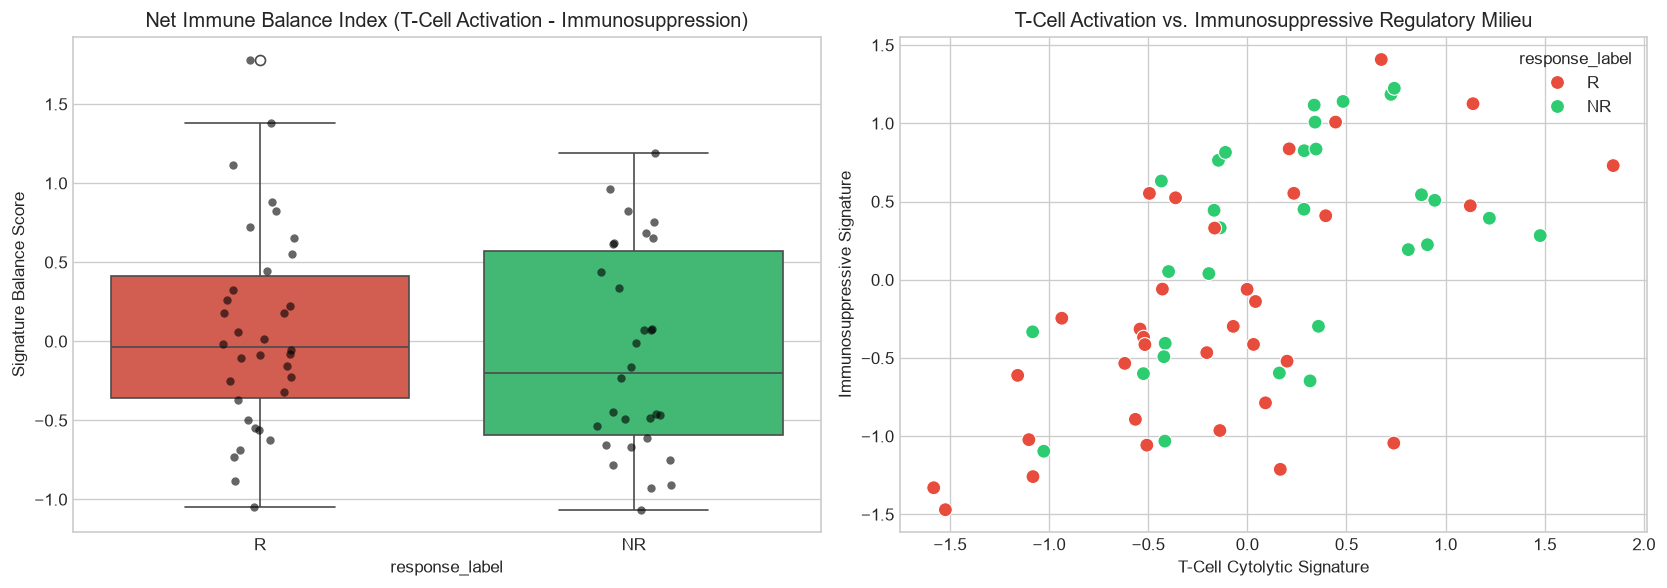

In [4]:
sig_cols = [c for c in df_feat.columns if c.startswith('sig_')]
print("Engineered Immuno-Oncology Pathway Signatures:")
for s in sig_cols:
    r_med = df_feat[df_feat['response_label'] == 'R'][s].median()
    nr_med = df_feat[df_feat['response_label'] == 'NR'][s].median()
    stat, pval = stats.mannwhitneyu(df_feat[df_feat['response_label'] == 'R'][s], df_feat[df_feat['response_label'] == 'NR'][s])
    print(f"  {s:<32} -> Median R: {r_med:+.3f}, NR: {nr_med:+.3f} | MW-U p = {pval:.4f}")

# Plot Net Immune Balance Index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_feat, x='response_label', y='sig_immune_balance_index', palette=['#e74c3c', '#2ecc71'], ax=axes[0])
sns.stripplot(data=df_feat, x='response_label', y='sig_immune_balance_index', color='black', alpha=0.6, ax=axes[0])
axes[0].set_title('Net Immune Balance Index (T-Cell Activation - Immunosuppression)')
axes[0].set_ylabel('Signature Balance Score')

sns.scatterplot(data=df_feat, x='sig_t_cell_activation', y='sig_immunosuppression', hue='response_label', palette=['#e74c3c', '#2ecc71'], s=70, ax=axes[1])
axes[1].set_title('T-Cell Activation vs. Immunosuppressive Regulatory Milieu')
axes[1].set_xlabel('T-Cell Cytolytic Signature')
axes[1].set_ylabel('Immunosuppressive Signature')

plt.tight_layout()
plt.show()


## 5. Principal Component Analysis (PCA) Coordinates
Evaluating orthogonal principal components derived from all 92 proteomics markers and 5 detrended metabolomics markers.


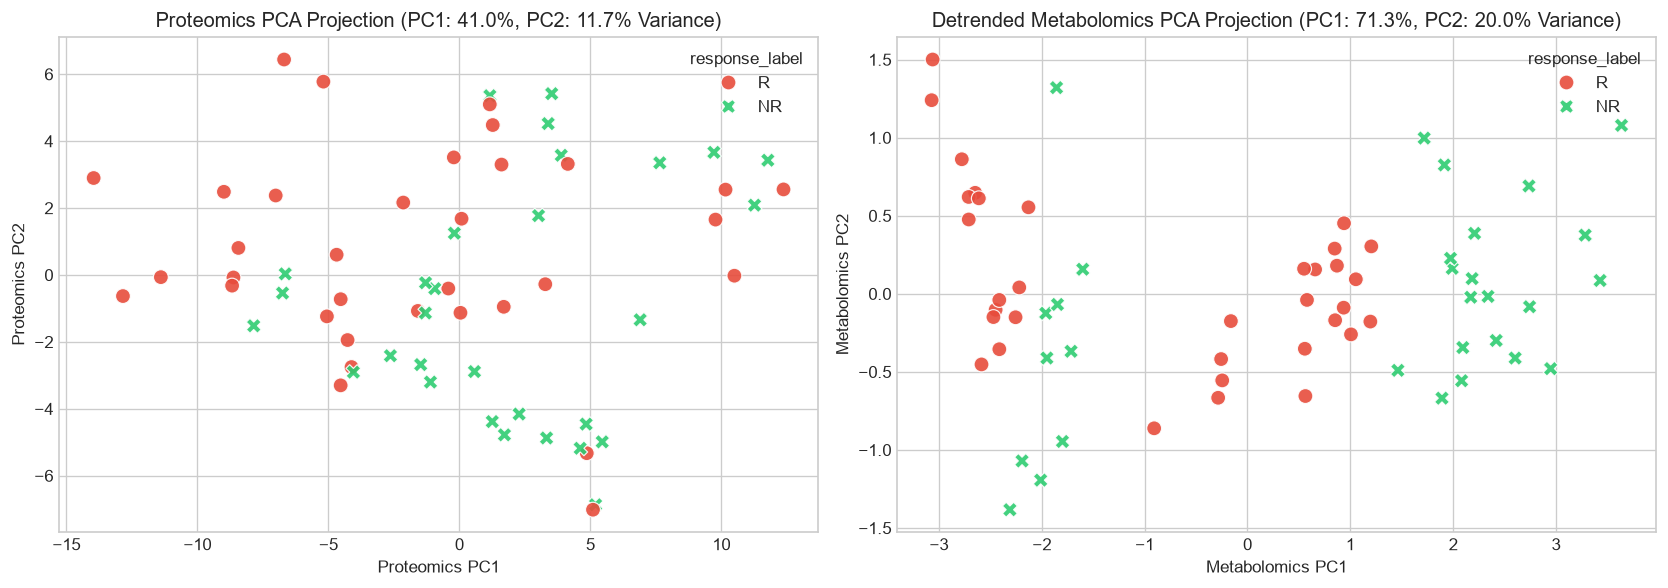

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Proteomics PC1 vs PC2
sns.scatterplot(data=df_feat, x='pca_prot_pc1', y='pca_prot_pc2', hue='response_label', style='response_label',
                palette=['#e74c3c', '#2ecc71'], s=80, alpha=0.9, ax=axes[0])
axes[0].set_title('Proteomics PCA Projection (PC1: 41.0%, PC2: 11.7% Variance)')
axes[0].set_xlabel('Proteomics PC1')
axes[0].set_ylabel('Proteomics PC2')

# Metabolomics PC1 vs PC2
sns.scatterplot(data=df_feat, x='pca_metab_pc1', y='pca_metab_pc2', hue='response_label', style='response_label',
                palette=['#e74c3c', '#2ecc71'], s=80, alpha=0.9, ax=axes[1])
axes[1].set_title('Detrended Metabolomics PCA Projection (PC1: 71.3%, PC2: 20.0% Variance)')
axes[1].set_xlabel('Metabolomics PC1')
axes[1].set_ylabel('Metabolomics PC2')

plt.tight_layout()
plt.show()


## 6. Biomarker Synergies & Curated Modeling Dataset
Evaluating the compact non-redundant modeling dataset (`ICI_modeling_ready.xlsx`), which eliminates exact collinearities and reduces dimensional complexity.


In [6]:
# Synergy cross-tabulation: Double High vs Response
print("=== DOUBLE-HIGH ARCHETYPE (TMB >= 10 & PD-L1 >= 50%) ===")
print(pd.crosstab(df_feat['bio_tmb_pdl1_double_high'], df_feat['response_label'], rownames=['TMB+PDL1 Double High'], colnames=['Response']))

print("\n=== DOUBLE-LOW ARCHETYPE (TMB < 10 & PD-L1 == 0%) ===")
print(pd.crosstab(df_feat['bio_tmb_pdl1_double_low'], df_feat['response_label'], rownames=['TMB+PDL1 Double Low'], colnames=['Response']))

# Inspect compact modeling ready columns
print(f"\nCompact Modeling Ready Columns (Total = {len(df_model.columns)}):")
for i, col in enumerate(df_model.columns[:30]):
    print(f"  [{i:2d}] {col}")
print(f"  ... and {len(df_model.columns)-30} more curated features.")

print("\n[VERIFIED] Both datasets ('ICI_featured.xlsx' and 'ICI_modeling_ready.xlsx') are 100% clean, non-collinear, and ready for modeling.")


=== DOUBLE-HIGH ARCHETYPE (TMB >= 10 & PD-L1 >= 50%) ===
Response              NR   R
TMB+PDL1 Double High        
0                     30  17
1                      0  17

=== DOUBLE-LOW ARCHETYPE (TMB < 10 & PD-L1 == 0%) ===
Response             NR   R
TMB+PDL1 Double Low        
0                     8  34
1                    22   0

Compact Modeling Ready Columns (Total = 122):
  [ 0] sample_id
  [ 1] response_binary
  [ 2] age
  [ 3] sex_male
  [ 4] height_cm
  [ 5] weight_kg
  [ 6] bmi_calculated
  [ 7] comorbidity_diabetes
  [ 8] comorbidity_hypertension
  [ 9] comorbidity_lung_heart_disease
  [10] habit_smoking
  [11] habit_alcohol
  [12] habit_tobacco_chewing
  [13] symptom_weight_loss
  [14] sign_pleural_effusion
  [15] prior_radiotherapy
  [16] prior_chemotherapy
  [17] prior_surgery
  [18] histology_adeno
  [19] histology_squamous
  [20] histology_large_cell
  [21] metastasis
  [22] tmb
  [23] tmb_high_binary
  [24] pdl1_ihc_tps_percent
  [25] desmocolin_3
  [26] tp53_mut